# 사전 준비

In [1]:
import warnings
warnings.filterwarnings('ignore')
import re, os, json
from textwrap import dedent
from pprint import pprint

In [2]:
from langchain_community.document_loaders import TextLoader
from langchain_community.document_loaders import PyPDFLoader
from langchain_community.document_loaders import JSONLoader
from langchain_core.documents import Document
from langchain_text_splitters import CharacterTextSplitter
from langchain_text_splitters import RecursiveCharacterTextSplitter
from transformers import AutoTokenizer
from langchain_openai import OpenAIEmbeddings
from langchain_huggingface.embeddings import HuggingFaceEmbeddings
from langchain_chroma import Chroma
from langchain_core.prompts import PromptTemplate
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI
from langchain_core.output_parsers import StrOutputParser

In [3]:
from dotenv import load_dotenv
load_dotenv()

True

## LangGraph에서 사용할 라이브러리

`TypedDict`: LangGraph 전반에 걸쳐 공유되는 상태 데이터의 구조를 정의한다.  
`List`: 리스트 안에 어떤 종류의 데이터가 들어가는지 대괄호 안에 지정할 수 있다.  
`Literal`: 함수가 리턴할 수 있는 값을 특정 문자열로 제한한다.

In [4]:
from typing import TypedDict, List, Literal

`START`: LangGraph의 시작을 의미한다.  
`END`: LangGraph의 끝을 의미한다.  
`StateGraph`: 노드와 엣지를 담는 전체 그래프 구조를 만든다.

In [5]:
from langgraph.graph import START, END, StateGraph

C:\miniconda3\envs\AI_LangGraph\Lib\site-packages\langgraph\checkpoint\base\__init__.py:18: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


`Image`: 이미지 파일 데이터를 이미지 객체로 변환한다.  
`display`: 이미지를 화면에 출력한다.

In [6]:
from IPython.display import Image, display

# 리듀서(Reducer) 활용하기
<br>
<img src="./reducer.png" width="1000" align="left" />

<img src="./reducer2.png" width="1200" align="left" />

리듀서는 프로그래밍에서 여러 개의 값이나 이전 상태를 입력받아, 이를 누적·조합하여 새로운 단일 값이나 상태를 만들어내는 함수를 의미하고 LangGraph에서는 상태 업데이트를 관리하는 중요한 개념으로 그래프의 각 노드의 출력을 그래프의 상태에 통합하는 방법을 정의한다.

리듀서의 필요성  
▶ 기본적으로 각 노드의 반환 값은 해당 상태 키의 이전 값을 덮어쓰는 방식으로 동작한다. => 상태 덮어쓰기(override)  
▶ 메시지 리스트와 같은 경우, 이전 상태에 새로운 값을 추가하고 싶을 때가 있다. => 누적 업데이트

## 리듀서를 지정하지 않은 경우 - 기본 리듀서(상태 덮어쓰기)

기본 리듀서는 상태에 대해 별도의 설정 없이 사용할 때 자동으로 적용되는 방식으로 리듀서를 별도로 지정하지 않은 경우 기존 값을 덮어쓰는 방식으로 동작한다.

LangGraph를 사용해서 상태(State)를 정의하고, 각 노드(Node)에서 그 상태를 어떻게 변화시키는지 확인한다.

상태(State)를 정의한다.  
상태는 그래프 전체에서 `노드(Node)들이 공유`하는 데이터 구조(Schema)를 의미한다.

In [7]:
class DocumentState(TypedDict):
    # key: key에 할당될 value의 자료형
    query: str # 사용자 질문
    documents: List[str] # 검색된 문서들

노드(Node)를 정의한다.  
노드는 그래프에서 실제 작업을 수행하는 함수를 의미하며 함수의 `리턴값으로 상태의 일부를 업데이트` 한다.  
함수를 만들 때 `인수`로 그래프의 모든 노드들이 `공유할 상태`를 지정해야 한다.

In [8]:
def node1(state: DocumentState) -> DocumentState:
    print('----- node1(사용자 질문 업데이트) -----')
    # 상태에서 사용자 질문을 가져온다.
    query = state['query']
    # 사용자 질문으로 상태를 업데이트 한다.
    return {'query': query}

In [9]:
def node2(state: DocumentState) -> DocumentState:
    print('----- node2(검색된 문서들 업데이트) -----')
    # 사용자 질문으로 검색된 문서들로 상태를 업데이트 한다.
    return {'documents': ['문서1', '문서2', '문서3']}

In [10]:
def node3(state: DocumentState) -> DocumentState:
    print('----- node3(추가로 검색된 문서들 업데이트) -----')
    # 사용자 질문으로 추가로 검색된 문서들로 상태를 업데이트 한다.
    return {'documents': ['문서2', '문서3', '문서4']}

LangGraph 객체를 만든다.  
StateGraph 클래스 생성자로 그래프의 `모든 노드들이 공유`해서 사용할 `상태`를 넘겨야 한다.

In [11]:
builder = StateGraph(state_schema=DocumentState)

LangGraph 객체에 노드들을 추가한다.  
add_node() 메소드의 `node` 속성에 노드를 식별하기 위한 고유 `이름`을 지정하고 `action` 속성에 이 노드가 실행될 때 실제 실행할 `함수 이름`을 지정한다.

In [12]:
builder.add_node(node='node1', action=node1)
builder.add_node(node='node2', action=node2)
builder.add_node(node='node3', action=node3)

LangGraph 객체에 노드들을 연결하는 엣지를 추가한다.  
add_edge() 메소드의 `start_key` 속성에 엣지가 시작되는 `출발지`를 지정하고 `end_key` 속성에 엣지가 도착하는 `목적지`를 지정한다.

In [13]:
builder.add_edge(start_key=START, end_key='node1')
builder.add_edge(start_key='node1', end_key='node2')
builder.add_edge(start_key='node2', end_key='node3')
builder.add_edge(start_key='node3', end_key=END)

LangGraph 객체를 컴파일한다.

In [14]:
graph = builder.compile()

컴파일된 LangGraph 객체를 이미지로 확인한다.

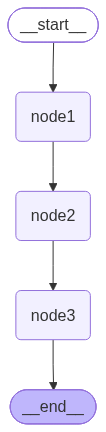

In [15]:
display(Image(graph.get_graph().draw_mermaid_png()))

LangGraph를 실행한다.  
invoke() 메소드의 인수로 그래프의 모든 노드가 공유해서 사용하는 `상태로 전달할 데이터`를 넘겨서 그래프를 실행한다.  
상태로 전달할 데이터는 반드시 `딕셔너리` 형태로 만들어야 하고 key는 반드시 `상태에 존재`하는 key를 사용해야 한다.

In [16]:
# 상태로 전달할 데이터를 딕셔너리 형태로 정의한다.
query = {'query': '삼성 폴더블 스마트폰을 추천해 주세요.'}
# invoke() 메소드를 실행하면 상태로 전달할 데이터가 상태에 저장된다.
final_state = graph.invoke(query)
print('최종 상태:', final_state)

----- node1(사용자 질문 업데이트) -----
----- node2(검색된 문서들 업데이트) -----
----- node3(추가로 검색된 문서들 업데이트) -----
최종 상태: {'query': '삼성 폴더블 스마트폰을 추천해 주세요.', 'documents': ['문서2', '문서3', '문서4']}


## 리듀서를 지정한 경우 - add 리듀서(누적 업데이트)

`from typing import TypedDict, List, Literal`  
`from langgraph.graph import START, END, StateGraph`  
`from IPython.display import Image, display`

파이썬 기본 연산자 중 하나인 더하기(+) 함수를 사용하기 위해 import 한다.  
LangGraph에서 새로운 데이터를 기존 데이터 뒤에 `붙이는 용도`로 사용된다. 

In [17]:
from operator import add

특정 타입에 추가적인 정보(메타 데이터)를 넣어주기 위해서 Annotated를 import 한다.

In [18]:
from typing import Annotated

상태(State)를 정의한다.

In [19]:
class ReducerState(TypedDict):
    query: str
    # documents: List[str] # add 리듀서가 적용되지 않은 경우    
    # documents에 새로운 값이 들어오면 add 함수(리듀서)를 사용해서 기존 값에 추가한다.
    # 만약 여러 노드에서 documents에 값을 보낸다면, 기존 값을 지우지 말고 add 함수를 사용해서 리스트 끝에 계속 이어 붙인다.
    documents: Annotated[List[str], add]

노드(Node)를 정의한다.

In [20]:
def node1(state: ReducerState) -> ReducerState:
    print('----- node1(사용자 질문 업데이트) -----')
    query = state['query']
    return {'query': query}

def node2(state: ReducerState) -> ReducerState:
    print('----- node2(검색된 문서들 업데이트) -----')
    return {'documents': ['문서1', '문서2', '문서3']}

def node3(state: ReducerState) -> ReducerState:
    print('----- node3(추가로 검색된 문서들 업데이트) -----')
    return {'documents': ['문서2', '문서3', '문서4']}

LangGraph 객체를 만든다.

In [21]:
builder = StateGraph(state_schema=ReducerState)

LangGraph 객체에 노드들을 추가한다.

In [22]:
builder.add_node('node1', node1)
builder.add_node('node2', node2)
builder.add_node('node3', node3)

LangGraph 객체에 노드들을 연결하는 엣지를 추가한다.

In [23]:
builder.add_edge(START, 'node1')
builder.add_edge('node1', 'node2')
builder.add_edge('node2', 'node3')
builder.add_edge('node3', END)

LangGraph 객체를 컴파일한다.

In [24]:
graph = builder.compile()

컴파일된 LangGraph 객체를 이미지로 확인한다.

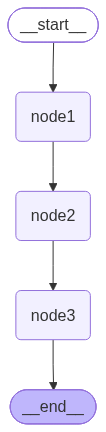

In [25]:
display(Image(graph.get_graph().draw_mermaid_png()))

LangGraph를 실행한다.

In [26]:
query = {'query': '삼성 폴더블 스마트폰을 추천해 주세요.'}
final_state = graph.invoke(query)
print('최종 상태:', final_state)

----- node1(사용자 질문 업데이트) -----
----- node2(검색된 문서들 업데이트) -----
----- node3(추가로 검색된 문서들 업데이트) -----
최종 상태: {'query': '삼성 폴더블 스마트폰을 추천해 주세요.', 'documents': ['문서1', '문서2', '문서3', '문서2', '문서3', '문서4']}


## 리듀서를 지정한 경우 - custom 리듀서

상태 업데이트가 기본적인 덮어쓰기나 뒤에 추가하는 방법만으로 해결되지 않을 때 사용하는 방법으로 중복 제거 등 `특정 비즈니스 로직이 필요`한 경우 사용한다.

`from typing import TypedDict, List, Literal, Annotated`  
`from langgraph.graph import START, END, StateGraph`  
`from IPython.display import Image, display`

custom 리듀서로 사용할 함수를 정의한다.

In [27]:
# 함수의 인수로 두 개의 리스트를 넘겨받아 두 리스트를 합쳐서 중복되는 데이터를 제거해서 리턴한다.
# left는 현재 상태에 저장되어 있던 기존 데이터이고 right는 노드에서 return되는 새 데이터를 의미한다.
# list | None는 left나 right로 넘어오는 데이터가 있을 수도(list) 있고 없을 수도(None) 있는 경우를 대비한 타입 설정이다.
def unique_document(left: list | None, right: list | None) -> list:
    '''두 개의 문서 리스트를 결합하고, 중복된 항목은 제거하세요.'''
    # 만약 기존 데이터(left)나 새 데이터(right)가 비어있다면, 오류를 방지하기 위해 빈 리스트로 초기화 시킨다.
    if not left:
        left = []
    if not right:
        right = []
    # 두 리스트를 하나로 합치고 set() 생성자 함수로 중복을 제거한 후 list() 생성자 함수로 리스트로 만들어 리턴시킨다.
    return list(set(left + right))

상태(State)를 정의한다.

In [28]:
class CustomReducerState(TypedDict):
    query: str
    # 위에서 만든 custom 리듀서 함수인 unique_document를 실행한다.
    documents: Annotated[List[str], unique_document]

노드를 만들고 노드와 엣지로 LangGraph 객체를 만들어 실행한다.

In [29]:
def node1(state: CustomReducerState) -> CustomReducerState:
    print('----- node1(사용자 질문 업데이트) -----')
    query = state['query']
    return {'query': query}

def node2(state: CustomReducerState) -> CustomReducerState:
    print('----- node2(검색된 문서들 업데이트) -----')
    return {'documents': ['문서1', '문서2', '문서3']}

def node3(state: CustomReducerState) -> CustomReducerState:
    print('----- node3(추가로 검색된 문서들 업데이트) -----')
    return {'documents': ['문서2', '문서3', '문서4']}

builder = StateGraph(state_schema=CustomReducerState)

builder.add_node('node1', node1)
builder.add_node('node2', node2)
builder.add_node('node3', node3)

builder.add_edge(START, 'node1')
builder.add_edge('node1', 'node2')
builder.add_edge('node2', 'node3')
builder.add_edge('node3', END)

graph = builder.compile()

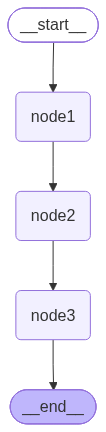

In [30]:
display(Image(graph.get_graph().draw_mermaid_png()))

In [31]:
query = {'query': '삼성 폴더블 스마트폰을 추천해 주세요.'}
final_state = graph.invoke(query)
print('최종 상태:', final_state)

----- node1(사용자 질문 업데이트) -----
----- node2(검색된 문서들 업데이트) -----
----- node3(추가로 검색된 문서들 업데이트) -----
최종 상태: {'query': '삼성 폴더블 스마트폰을 추천해 주세요.', 'documents': ['문서2', '문서1', '문서3', '문서4']}


# 메시지 그래프(Message Graph)와 피드백 루프(Feedback Loop)


## 메시지 그래프

메시지 그래프는 LangGraph에서 `챗봇`이나 `대화형 에이전트`를 쉽고 빠르게 구축할 수 있도록 만들어서 `제공`되는 그래프 클래스이다.  
StateGraph를 사용하려면 상태(State) 구조를 직접 설계하고 리듀서 함수까지 일일이 정의해야 하지만, 메시지 그래프는 대화 메시지(HumanMessage, AIMessage) 관리에 특화되어 있어 이러한 초기 설정 과정을 대폭 생략할 수 있다.

<img src="./messageGraph.png" width="1200" align="left" />

## 피드백 루프

`조건부 엣지`를 활용하여 반복적인 작업을 수행하는 그래프로 평가 결과를 바탕으로 응답을 다시 생성하는 과정이 `반복`된다.

<img src="./messageGraph2.png" width="1200" align="left" />

## Message State 정의

이전 대화 기록을 그래프 상태에 메시지 목록으로 저장할 때 유용하다.  
그래프 상태에 Message 객체 목록을 저장하는 key를 추가하고, 이 key에 리듀서 함수를 추가한다.

리듀서 함수  
▶ operator.add 함수  
&nbsp;&nbsp;&nbsp;새 메시지를 기존 목록에 단순히 추가만 한다.  
▶ add_message 함수  
&nbsp;&nbsp;&nbsp;새 메시지는 기존 목록에 추가한다.  
&nbsp;&nbsp;&nbsp;메시지 ID를 추적해서 기존 메시지 업데이트도 올바르게 처리한다.

LangGraph에서 대화 기록(Chat History)을 관리할 때 표준으로 사용되는 상태 정의 방식으로 add_message라는 리듀서를 사용하여 AI와 사용자 간의 대화 내용을 유실 없이 관리하는 것이 목적이다.

`from typing import TypedDict, Annotated, List`  
`from langchain_core.documents import Document`

LangChain이 사용하는 모든 종류의 메시지(HumanMessage(사용자), AIMessage(AI 답변), SystemMessage(시스템 지짐) 등)를 모두 담을 수 있는 포괄적인(추상) 메시지 타입을 사용하기 위해 AnyMessage를 import 한다.

In [32]:
from langchain_core.messages import AnyMessage

노드가 새로운 메시지를 반환했을 때, 대화 기록을 덮어쓰는 것이 아니라 기존 리스트에 새로운 메시지를 안전하게 누적시키기 위해서 add_messages를 import 한다.

In [33]:
from langgraph.graph.message import add_messages

상태(State)를 정의한다. - add_messages 리듀서 사용

In [34]:
class GraphState(TypedDict):
    # List[AnyMessage]는 메시지 객체(AnyMessage)들이 저장된 리스트임을 의미한다. 다양한 메시지 객체가 저장되는 리스트이다.
    # add_messages는 리스트에 새로운 데이터가 들어올 때 적용할 메시지 전용 합치기 규칙(리듀서)을 지정해서 새로운 대화로 덮어쓰지 말고 누적하라고 지시한다.
    messages: Annotated[List[AnyMessage], add_messages]
    # AI가 질문에 답하기 위해서 외부에서 찾아온 참조 문서들을 저장하는 리스트이다.
    documents: List[Document]
    # 답변의 품질이나 문서의 관련성을 숫자로 저장한다.
    grade: float
    # AI가 답변 생성을 몇 번이나 시도했는지 저장한다.
    num_generation: int

In [35]:
GraphState.__annotations__.keys()

dict_keys(['messages', 'documents', 'grade', 'num_generation'])

add를 사용하는 일반적인 리스트 합치기와 add_messages의 차이점은 관리의 지능화에 있다.

대화의 연속성을 유지하기 하기 위해서 사용자가 질문하고 AI가 답할 때마다 메시지를 차곡차곡 쌓아서 전체 맥락을 유지하게 한다.  
동일한 ID를 가진 메시지가 들어오면 리스트가 무한정 길어지는 대신 해당 메시지만 업데이트(중복 방지)하므로, 메모리를 효율적으로 관리할 수 있고 답변 수정 기능을 구현하기 쉽다.

이 구조를 사용하면 별도의 복잡한 로직 없이도 이전 대화를 기억하는 챗봇에 활용할 수 있다.

사용자와 AI의 내화 내역을 알아서 누적해주는 기능을 사용하기 위해 MessagesState를 import 한다.  

In [36]:
from langgraph.graph import MessagesState

상태(State)를 정의한다. - MessagesState 객체 사용  
MessagesState 클래스를 상속받아서 상태를 정의하면 우리가 직접 정의하지 않아도 대화 기록을 자동으로 누적해주는 아래와 같은 `messages` key가 자동으로 생성된다.  
`messages: Annotated[List[AnyMessage], add_messages]`

In [37]:
class GraphState(MessagesState):
    # MessagesState 클래스를 상속받으면 messages가 기본적으로 제공된다.
    # messages: Annotated[List[AnyMessage], add_messages]
    documents: List[Document]
    grade: float
    num_generation: int

In [38]:
GraphState.__annotations__.keys()

dict_keys(['messages', 'documents', 'grade', 'num_generation'])

## RAG Chain을 구성한다.

사용자의 질문을 받으면 벡터저장소에서 관련 내용을 찾아낸 뒤, 그 내용을 바탕으로 AI가 답변을 생성하는 RAG chain을 구성한다.

`from langchain_chroma import Chroma`  
`from langchain_openai import ChatOpenAI`  
`from langchain_core.prompts import ChatPromptTemplate`  
`from langchain_core.output_parsers import StrOutputParser`  

로컬 AI 엔진인 Ollama를 이용해서 텍스트를 숫자의 나열(벡터)로 변환해 주는 임베딩 기능을 사용하기 위해 OllamaEmbeddings을 import 한다.

In [39]:
from langchain_ollama import OllamaEmbeddings

입력되는 데이터를 변형 없이 그대로 넘겨주기 위해 RunnablePassthrough를 import 한다.

In [40]:
from langchain_core.runnables import RunnablePassthrough

사용자가 LLM에게 던지는 질문을 저장하기 위해 HumanMessage를 import 한다.  
LLM이 사용자의 질문에 답변한 텍스트를 저장하기 위해 AIMessage를 import 한다.  

In [41]:
from langchain_core.messages import HumanMessage, AIMessage

벡터저장소를 만들 때 사용했던 임베딩 모델을 불러온 후 벡터저장소를 불러와서 벡터검색기를 만든다.

In [42]:
embeddings_model = OllamaEmbeddings(model='bge-m3')

menu_db = Chroma(
    # 벡터저장소를 생성할 때 사용했던 임베딩 모델을 지정한다.
    embedding_function=embeddings_model,
    collection_name='restaurant_menu',
    persist_directory='./chroma_db'
)
print(menu_db._collection.count())

menu_retriever = menu_db.as_retriever(search_kwargs={'k': 2})

# 벡터검색기로 검색한 결과를 하나의 문자열로 합치는 함수
def format_docs(docs):
    return '\n'.join(doc.page_content for doc in docs)

10


LLM 모델 불러오고 프롬프트를 구성한다.

In [43]:
llm = ChatOpenAI(model='gpt-4o-mini')

system = dedent('''
    당신은 도움이 되는 어시스턴트입니다. 다음 문맥(context)을 사용하여 사용자의 질문에 답하세요.
    문맥(context):
    {context}
''')

prompt = ChatPromptTemplate.from_messages([
    ('system', system),
    ('human', '{question}')
])

RAG chain을 구성한다.

In [44]:
# context는 벡터검색기로 검색한 결과를 하나의 문자열로 합치는 함수를 실행한 결과를 chain으로 구성한다.
# question은 데이터 변형없이 그대로 파이프로 넘겨주기 위해서 RunnablePassthrough를 사용한다.
rag_chain = {'context': menu_retriever | format_docs, 'question': RunnablePassthrough()} | prompt | llm | StrOutputParser()

RAG chain을 실행한다.

In [45]:
question = '채식주의자를 위한 메뉴를 추천해주세요.'
response = rag_chain.invoke(question)
print(response)

채식주의자를 위한 메뉴로는 "가든 샐러드"를 추천드립니다. 이 샐러드는 유기농 믹스 그린, 체리 토마토, 오이, 당근으로 구성되어 있으며, 건강한 재료들로 신선한 맛을 제공합니다. 또한, 발사믹 드레싱이 채소의 본연의 맛을 살려줍니다. 가격은 ₩12,000입니다.


## 노드(Node)를 정의한다.

RAG chain을 실행해서 LLM의 답변을 얻어와서 상태를 업데이트하는 노드, 검색 및 응답 단계

In [46]:
def retriever_response(state: GraphState) -> GraphState:
    # 사용자의 질문(현재 상태의 메시지 기록 중 가장 마지막 메시지)을 추출한다.
    # state['messages']는 사용자와 AI가 주고받은 대화 내역이 저장되어 있으므로 마지막 대화 내화 내역만 얻어오려면 [-1]을 사용해서 인덱싱한다.
    last_message = state['messages'][-1]
    # 사용자의 질문이 저장된 메시지 객체에서 실제 텍스트 내용만 뽑아낸다.
    # last_message에는 HumanMessage 객체가 저장되어 있으므로 질문 텍스트만 얻어오기 위해서 content 속성에 접근해서 얻어온다.
    query = last_message.content
    # 사용자의 질문에 관련된 문서를 벡터검색기에서 검색한다.
    retriever_docs = menu_retriever.invoke(query)
    # 사용자 질문으로 RAG chain을 실행해서 최종 답변을 생성한다.
    response = rag_chain.invoke(query)
    # 상태(messages, documents)를 업데이트 한다.
    return {
        # AI가 응답한 답변을 AIMessage 객체로 만들어서 상태를 업데이트 한다. add_messages 리듀서가 적용되서 대화 내용을 추가한다.
        'messages': [AIMessage(content=response)],
        # 나중에 출처를 확인하거나 다른 노드에서 참조할 수 있도록 벡터검색기로 검색된 문서 리스토 상태를 업데이트 한다. 검색된 문서를 덮어쓴다.
        'documents': retriever_docs
    }

데이터 모델(클래스)을 정의할 때 반드시 상속받아야 하는 BaseModel을 import 한다.  
데이터 모델을 구성하는 각 필드에 대한 제약 조건을 추가하기 위해 Field를 import 한다.  

In [47]:
from pydantic import BaseModel, Field

LLM의 응답에 대한 점수의 데이터 구조 클래스를 정의한다.

In [48]:
class GradeResponse(BaseModel):
    '''정답에 대한 점수'''
    # score라는 필드는 필수 항목(...)이고 0이상(ge, Greater then or Equal)이고 1이하(le, Less then or Equal)이어야 한다는 제약 조건을 설정한다.
    score: float = Field(..., ge=0, le=1, description='점수는 0이상 1이하의 실수이다.')
    # explanation라는 필드는 필수 항목(...)이고 점수를 왜 그렇게 주었는지 이유가 저장된다.
    explanation: str = Field(..., deprecated='부여된 점수에 대한 설명')

In [49]:
print(json.dumps(GradeResponse.model_json_schema(), ensure_ascii=False, indent=2))

{
  "description": "정답에 대한 점수",
  "properties": {
    "score": {
      "description": "점수는 0이상 1이하의 실수이다.",
      "maximum": 1,
      "minimum": 0,
      "title": "Score",
      "type": "number"
    },
    "explanation": {
      "deprecated": true,
      "title": "Explanation",
      "type": "string"
    }
  },
  "required": [
    "score",
    "explanation"
  ],
  "title": "GradeResponse",
  "type": "object"
}


RAG chain을 실행해서 얻어온 LLM의 답변 질문의 맥락(context)에 부합하는지 환각(Hallucination) 체크 또는 자기 수정(Self-Correction)하는 노드, 답변 채점 단계

In [50]:
def answer_grade(state: GraphState) -> GraphState:
    messages = state['messages']
    # 사용자의 질문(현재 상태의 메시지 기록 중 뒤에서 두 번째 메시지)을 추출한다.
    question = messages[-2].content
    # 사용자의 질문에 대한 AI의 답변(현재 상태의 메시지 기록 중 가장 마지막 메시지)을 추출한다.
    answer = messages[-1].content
    # AI가 답변 생성에 참고한 벡터검색기에서 검색해온 문서를 추출해서 하나의 문자열로 변환해서 저장한다.
    context = format_docs(state['documents'])
    
    # 채점 프롬프트를 구성한다.
    # LLM에게 역할을 부여하고 채점 기준을 작성한다.
    system = dedent('''
        당신은 전문적인 채점관입니다.
        주어진 맥락(context)을 고려하여, 질문(question)에 대한 답변(answer)의 관련성과 정확도를 평가해주세요.
        정확도 점수는 0에서 1 사이로 부여하고, 그에 대한 이유도 함께 설명해주세요.
    ''')
    # 채점에 필요한 세 가지 요소(질문, 맥락, 답변)를 LLM에게 전달하는 형식을 작성한다.
    human = dedent('''
        [질문(question)]:
        {question}
        [맥락(context)]:
        {context}
        [답변(answer)]:
        {answer}
        [점수(grade)]:
    ''')
    prompt = ChatPromptTemplate.from_messages([
        ('system', system),
        ('human', human)
    ])
    
    # 채점하는 RAG chain을 생성하고 실행한다.
    # with_structured_output() 메소드의 인수로 데이터 모델을 넘겨서 데이터 모델의 형태에 정확히 맞춰서 응답하게 한다.
    rag_chain = prompt | llm.with_structured_output(schema=GradeResponse)
    # RAG chain을 실행할 때 프롬프트의 변수로 전달할 데이터들을 딕셔너리 형태로 넘겨서 실행한다.
    response = rag_chain.invoke({'question': question, 'context': context, 'answer': answer})
    
    # 답변 생성 횟수를 현재 상태에서 가져와서 1증가 시킨다.
    # 그래프가 최초로 실행될 때 상태에 num_generation이 없으므로 0으로 초기화한다.
    num_generation = state.get('num_generation', 0)
    num_generation += 1
    
    # 상태(grade, num_generation)를 업데이트 한다.
    return {
        # RAG chain이 실행되면 응답 결과는 GradeResponse 클래스 타입이므로 점수만 꺼내오기 위해서 score 속성을 지정한다.
        'grade': response.score,
        'num_generation': num_generation
    }

## 조건부 엣지를 정의한다.

`from typing import Literal`

채점 결과나 반복 횟수에 따라서 다음 단계를 어떤 노드로 보낼지 결정한다.

In [51]:
def conditional_edge(state: GraphState) -> Literal['generate', 'retriever_response_node']:
    # 채점 결과를 출력한다.
    print('점수:', state['grade'])
    
    # 최대 채점 횟수(2번)를 제한해서 무한 루프 방지한다.
    if state['num_generation'] > 2:
        # 최대 채점 횟수보다 많이 시도했다면 더 이상 채점을 재시도하지 않고, 현재 결과를 그대로 종료 단계인 END로 가는 경유지 노드로 'generate'를 리턴한다.
        return 'generate'
    
    # 채점 결과를 기준 값(0.9)과 비교해서 점수가 낮다면 질문에 대한 답변을 재시도한다.
    if state['grade'] < 0.9:
        # 채점 결과가 기준 값보다 작다면, 문서를 다시 검색해서 답변을 새로 만들기 위해 
        return 'retriever_response_node'
    else:
        # 채점 결과가 기준 값 이상이라면, 현재 결과를 그대로 종료 단계인 END로 가는 경유지 노드로 'generate'를 리턴한다.
        return 'generate'

## 그래프를 구성한다.

`from langgraph.graph import START, END, StateGraph`

그래프 객체를 생성한다.

이 그래프는 GraphState에 정의된 데이터(메시지, 검색한 문서, 점수, 답변 생성 횟수)를 공유하고 업데이트를 한다.

In [52]:
builder = StateGraph(GraphState)

노드를 추가한다.

In [53]:
# 검색 및 응답 단계 노드
builder.add_node('retriever_response_node', retriever_response)
# 답변 채점 단계 노드
builder.add_node('answer_grade_node', answer_grade)

엣지를 추가한다.

In [54]:
builder.add_edge(START, 'retriever_response_node')
builder.add_edge('retriever_response_node', 'answer_grade_node')

# 조건부 엣지를 추가한다.
builder.add_conditional_edges(
    # 조건 검사를 시작할 출발지 노드를 지정한다.
    'answer_grade_node',
    # 조건 판단에 사용할 조건부 엣지로 사용할 함수를 지정한다.
    conditional_edge,
    # 조건 판단 결과 리턴되는 값에 따라 실제로 이동할 노드를 딕셔너리 형태로 지정한다.
    {
        # 조건 판단 결과 채점 횟수 초과 또는 채점 결과 기준 값 이상 이라면 'generate'가 리턴되고 LangGraph를 종료하기 위해 END로 엣지를 추가한다.
        'generate': END,
        # 조건 판단 결과 채점 횟수 미만이고 채점 결과 기준 값 미만 이라면 retriever_response_node'되고 'retriever_response_node'로 엣지를 추가한다.
        'retriever_response_node': 'retriever_response_node'
    }
)

## 그래프를 컴파일하고 시각화한다.

`from IPython.display import Image, display`

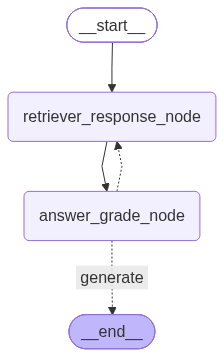

In [55]:
graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

## 그래프를 실행한다.

In [56]:
# 실행할 그래프로 전달할 초기 상태 값을 정의하는 딕셔너리를 만든다.
query = {
    'messages': [HumanMessage(content='채식주의자를 위한 메뉴를 추천해주세요.')]
}
# 그래프를 실행한다.
final_state = graph.invoke(query)
final_state

점수: 1.0


{'messages': [HumanMessage(content='채식주의자를 위한 메뉴를 추천해주세요.', additional_kwargs={}, response_metadata={}, id='7bba602b-65e7-4605-ba25-8df7f87575aa'),
  AIMessage(content='채식주의자를 위한 메뉴로는 가든 샐러드를 추천드립니다. 이 샐러드는 신선한 유기농 믹스 그린, 체리 토마토, 오이, 당근이 주요 식재료로 사용되며, 건강한 맛과 아삭한 식감을 제공합니다. 특제 발사믹 드레싱이 채소 본연의 맛을 살려주어 더욱 맛있게 즐길 수 있습니다. 가격은 ₩12,000입니다.', additional_kwargs={}, response_metadata={}, id='abbc312e-8be2-44ce-8153-ac1f1f49a9aa')],
 'documents': [Document(id='b2ea8e7a-b3bc-4bcf-b859-aef2f2d94a47', metadata={'source': './data/restaurant_menu.txt', 'menu_number': '5', 'menu_name': '가든 샐러드'}, page_content='5. 가든 샐러드\n    가격: ₩12,000\n    주요 식재료: 유기농 믹스 그린, 체리 토마토, 오이, 당근, 발사믹 드레싱\n    설명: 신선한 유기농 채소들로 구성된 건강한 샐러드입니다. 아삭한 식감의 믹스 그린에 달콤한 체리 토마토, 오이, 당근을 더해 다양한 맛과 식감을 즐길 수 있습니다. 특제 발사믹 드레싱이 채소 본연의 맛을 살려줍니다.'),
  Document(id='28eeb6f6-eaef-4b24-a060-47e4b0b455e9', metadata={'source': './data/restaurant_menu.txt', 'menu_name': '해산물 파스타', 'menu_number': '6'}, page_content='6. 해산물 파스타\n    가격: ₩24,000\n  

# 그라디오 챗봇 인터페이스 적용하기

`from langchain_core.messages import AIMessage, HumanMessage`

In [57]:
from typing import List, Tuple
import gradio as gr

사용자가 직접 타이핑하지 않아도 클릭만으로 질문을 할 수 있는 사용자 편의를 위한 예시 질문을 만든다.

In [58]:
example_questions = [
    '채식주의자를 위한 메뉴를 추천해주세요.',
    '커피와 어울리는 메뉴를 추천해주세요.',
    '파스타에 어울리는 음료를 추천해주세요.'
]

사용자가 챗봇에 메시지를 보낼 때마다 사용할 함수를 만든다.

In [105]:
# 현재 챗봇에 입력된 메시지(message)와 이전 대화 기록(history)을 받아 최종 답변을 문자열(str)로 리턴한다.
def answer_invoke(message: str, history: List[dict]) -> str:
    try:
        # 대화 기록을 LangChain 메시지 객체 리스트로 변환하여 담아둘 빈 리스트를 만든다.
        chat_history = []
        # 이전 대화 기록(history)을 하나씩 꺼내서 반복문을 돌면서 대화 내용을 추출한다.
        for msg in history:
            # print(msg)
            # 그라디오 대화 기록은 딕셔너리 형태(예: {'role': 'user', 'content': '안녕'})이므로 키 값을 참조하여 데이터를 가져온다.
            # 메시지의 역할(role)에 따라서 HumanMessage 객체 또는 AIMessage 객체를 만들어서 대화를 기록하는 리스트에 추가한다.
            if msg['role'] == 'user': # 메시지의 역할이 사용자(user)일 때
                chat_history.append(HumanMessage(content=msg['content']))
            elif msg['role'] == 'assistant': # 메시지의 역할(role)이 AI(assistant)일 때
                chat_history.append(AIMessage(content=msg['content']))
            # ===== if
        # ===== for
        
        # 실행할 그래프로 전달할 초기 상태 값을 정의하는 딕셔너리를 만든다.
        # print(chat_history[-2:])
        context = ''
        for chat in chat_history[-2:]:
            # print(chat.content[0]['text'])
            context += chat.content[0]['text']
            
        query = {
            # 대화 흐름을 유지(이전 대화를 참고)하기 위해 최근 대화와 방금 사용자가 보낸 새 메시지를 합쳐서 초기 상태 값을 정의한다.
            # chat_history[-2:]는 마지막 대화(질문, 답변)를 의미한다.
            # 'messages': chat_history[-2:] + [HumanMessage(content=message)]
            # 이전 대화가 저장된 객체에서 순순한 대화 내용만 얻어와사 초기 상태 값을 정의한다.
            'messages': [HumanMessage(content=context + message)]
        }
        # 그래프를 실행한다.
        final_state = graph.invoke(query)
        # 챗봇 채팅창에 AI의 답변이 나와야 하므로 그래프를 실행한 결과에서 마지막 데이터(AIMessage 객체)를 리턴시킨다.
        return final_state['messages'][-1].content
    except Exception as e:
        print(f'{e} 에러 발생')
        return '죄송합니다. 응답을 생성하는 동안 오류가 발생했습니다. 다시 시도해 주세요.'

In [106]:
with gr.Blocks(theme=gr.themes.Citrus()) as demo:
    gr.ChatInterface(
        fn=answer_invoke,
        title='레스토랑 메뉴 AI 어시스턴스',
        description='메뉴 정보, 추천, 음식 관련 질문에 답변해 드립니다.',
        # 예제 질문 리스트를 추가한다.
        examples=example_questions
    )

In [107]:
demo.launch()

* Running on local URL:  http://127.0.0.1:7872
* To create a public link, set `share=True` in `launch()`.


점수: 1.0
점수: 1.0
점수: 1.0
점수: 1.0
점수: 1.0
점수: 1.0


In [94]:
demo.close()

Closing server running on port: 7868
